[1] 392

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   9.00   17.00   22.75   23.45   29.00   46.60 

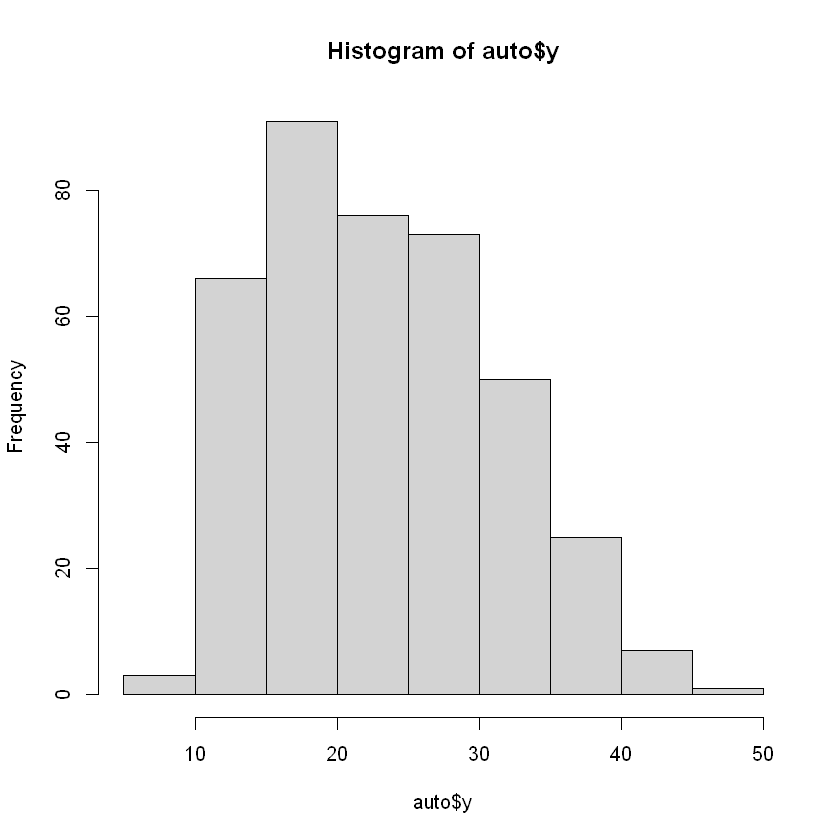


Call:
glm(formula = y ~ x2 + x3 + x4 + x5 + x6 + x7 + x8, family = Gamma(link = "log"), 
    data = auto)

Coefficients:
              Estimate Std. Error t value Pr(>|t|)    
(Intercept)  1.684e+00  1.658e-01  10.159  < 2e-16 ***
x2          -2.717e-02  1.139e-02  -2.386  0.01753 *  
x3           8.382e-04  2.713e-04   3.090  0.00215 ** 
x4          -1.486e-03  4.860e-04  -3.058  0.00239 ** 
x5          -2.701e-04  2.322e-05 -11.629  < 2e-16 ***
x6          -8.582e-04  3.482e-03  -0.246  0.80544    
x7           3.088e-02  1.836e-03  16.825  < 2e-16 ***
x82          9.079e-02  2.008e-02   4.522 8.20e-06 ***
x83          8.415e-02  1.959e-02   4.295 2.22e-05 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for Gamma family taken to be 0.01373834)

    Null deviance: 44.2046  on 391  degrees of freedom
Residual deviance:  5.3114  on 383  degrees of freedom
AIC: 1876.3

Number of Fisher Scoring iterations: 4


Start:  AIC=1876.26
y ~ x2 + x3 + x4 + x5 + x6 + x7 + x8

       Df Deviance    AIC
- x6    1   5.3123 1874.3
<none>      5.3114 1876.3
- x2    1   5.3898 1880.0
- x4    1   5.4366 1883.4
- x3    1   5.4419 1883.8
- x8    2   5.6772 1898.9
- x5    1   7.1816 2010.4
- x7    1   9.2419 2160.3

Step:  AIC=1874.32
y ~ x2 + x3 + x4 + x5 + x7 + x8

       Df Deviance    AIC
<none>      5.3123 1874.3
- x2    1   5.3901 1878.0
- x3    1   5.4456 1882.1
- x4    1   5.4957 1885.7
- x8    2   5.6773 1897.0
- x5    1   7.7375 2049.4
- x7    1   9.2623 2160.7



Call:
glm(formula = y ~ x2 + x3 + x4 + x5 + x7 + x8, family = Gamma(link = "log"), 
    data = auto)

Coefficients:
              Estimate Std. Error t value Pr(>|t|)    
(Intercept)  1.667e+00  1.494e-01  11.158  < 2e-16 ***
x2          -2.704e-02  1.136e-02  -2.381  0.01777 *  
x3           8.444e-04  2.696e-04   3.132  0.00187 ** 
x4          -1.411e-03  3.816e-04  -3.697  0.00025 ***
x5          -2.728e-04  2.041e-05 -13.367  < 2e-16 ***
x7           3.091e-02  1.828e-03  16.912  < 2e-16 ***
x82          9.059e-02  2.005e-02   4.519 8.30e-06 ***
x83          8.401e-02  1.956e-02   4.294 2.23e-05 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for Gamma family taken to be 0.01369889)

    Null deviance: 44.2046  on 391  degrees of freedom
Residual deviance:  5.3123  on 384  degrees of freedom
AIC: 1874.3

Number of Fisher Scoring iterations: 4


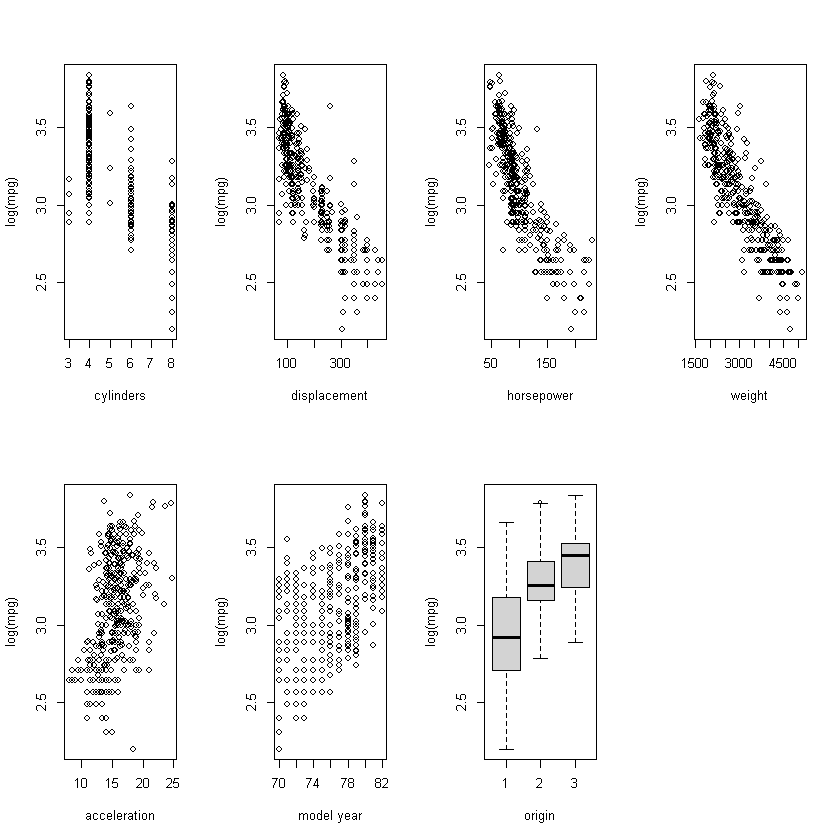

In [1]:
#########################################################################
# Leitura dos dados
#########################################################################
auto <- read.table("auto-mpg.data-original", head=F, sep="", na.strings="NA")
names(auto) <- c("y","x2","x3","x4","x5","x6","x7","x8","nome")
auto <- na.omit(auto)
rownames(auto) <- NULL
auto$x8 <- factor(auto$x8)
nrow(auto)

#########################################################################
# EXERCICIO 3
#########################################################################

# (a) Analise descritiva: log(y) contra cada preditora
hist(auto$y)
summary(auto$y)
par(mfrow=c(2,4))
plot(auto$x2, log(auto$y), xlab="cylinders",     ylab="log(mpg)")
plot(auto$x3, log(auto$y), xlab="displacement",  ylab="log(mpg)")
plot(auto$x4, log(auto$y), xlab="horsepower",    ylab="log(mpg)")
plot(auto$x5, log(auto$y), xlab="weight",        ylab="log(mpg)")
plot(auto$x6, log(auto$y), xlab="acceleration",  ylab="log(mpg)")
plot(auto$x7, log(auto$y), xlab="model year",    ylab="log(mpg)")
boxplot(log(auto$y) ~ auto$x8, xlab="origin", ylab="log(mpg)")
par(mfrow=c(1,1))

# (b) Selecao de variaveis (backward, AIC) a partir do modelo completo
aj0_auto <- glm(y ~ x2 + x3 + x4 + x5 + x6 + x7 + x8,
                family=Gamma(link="log"), data=auto)
summary(aj0_auto)

aj1_auto <- step(aj0_auto, direction="backward")
summary(aj1_auto)

# Modelo final (ajuste explicito)
aj_final <- glm(y ~ x2 + x3 + x4 + x5 + x7 + x8,
                family=Gamma(link="log"), data=auto)


In [4]:
# (c) Resultados e interpretacao (exp(beta) = razao multiplicativa na media)
summary(aj_final)
exp(coefficients(aj_final))
exp(confint.default(aj_final))


Call:
glm(formula = y ~ x2 + x3 + x4 + x5 + x7 + x8, family = Gamma(link = "log"), 
    data = auto)

Coefficients:
              Estimate Std. Error t value Pr(>|t|)    
(Intercept)  1.667e+00  1.494e-01  11.158  < 2e-16 ***
x2          -2.704e-02  1.136e-02  -2.381  0.01777 *  
x3           8.444e-04  2.696e-04   3.132  0.00187 ** 
x4          -1.411e-03  3.816e-04  -3.697  0.00025 ***
x5          -2.728e-04  2.041e-05 -13.367  < 2e-16 ***
x7           3.091e-02  1.828e-03  16.912  < 2e-16 ***
x82          9.059e-02  2.005e-02   4.519 8.30e-06 ***
x83          8.401e-02  1.956e-02   4.294 2.23e-05 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for Gamma family taken to be 0.01369889)

    Null deviance: 44.2046  on 391  degrees of freedom
Residual deviance:  5.3123  on 384  degrees of freedom
AIC: 1874.3

Number of Fisher Scoring iterations: 4


(Intercept)          x2          x3          x4          x5          x7 
  5.2970678   0.9733264   1.0008447   0.9985903   0.9997272   1.0313954 
        x82         x83 
  1.0948221   1.0876382

,2.5 %,97.5 %
(Intercept),3.9523732,7.0992607
x2,0.9519016,0.9952334
x3,1.0003160,1.0013737
x4,0.9978437,0.9993375
x5,0.9996873,0.9997672
x7,1.0277071,1.0350969
x82,1.0526359,1.1386989
x83,1.0467214,1.1301545


[1]  14 382 326 331 116

Proporcao fora do envelope: 0.1913265 


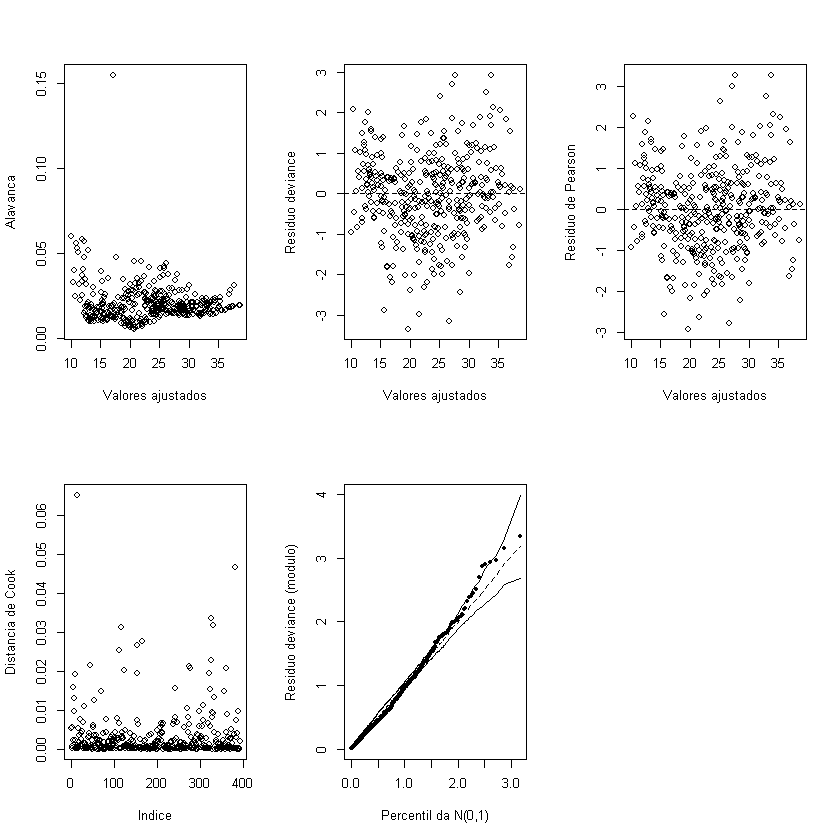

In [11]:
# (d) Analise de diagnostico
X <- model.matrix(aj_final)
w <- aj_final$weights
W <- diag(w)

par(mfrow=c(2,3))
# Pontos alavanca
auxh <- solve(t(X)%*%W%*%X)
H <- sqrt(W)%*%X%*%auxh%*%t(X)%*%sqrt(W)
h <- diag(H)
p <- length(coefficients(aj_final)); n <- nrow(auto)
plot(fitted(aj_final), h, xlab="Valores ajustados", ylab="Alavanca")
#identify(fitted(aj_final), h, n=3)

# Residuo deviance padronizado
aux_tdi <- resid(aj_final, type='deviance')
aux_fi <- summary(aj_final)
fi <- 1/aux_fi$dispersion
tdi <- aux_tdi*sqrt(fi/(1-h))
plot(fitted(aj_final), tdi, xlab="Valores ajustados", ylab="Residuo deviance")
abline(h=0, lty=2)
#identify(fitted(aj_final), tdi, n=3)

# Residuo de Pearson padronizado
aux_tsi <- resid(aj_final, type='pearson')
tsi <- aux_tsi*sqrt(fi/(1-h))
plot(fitted(aj_final), tsi, xlab="Valores ajustados", ylab="Residuo de Pearson")
abline(h=0, lty=2)

# Distancia de Cook
#identify(ldi, n=3)
#order(ldi, decreasing=TRUE)[1:5]
cook <- cooks.distance(aj_final)
order(cook, decreasing=TRUE)[1:5]
plot(cook, xlab="Indice", ylab="Distancia de Cook")
#identify(cook, n=5)

# Envelope simulado
envelope_glm <- function(fit, data, nsim=100, alpha=0.05){
  resp <- all.vars(formula(fit))[1]
  mu   <- fitted(fit)
  phi  <- summary(fit)$dispersion
  fam  <- fit$family$family
  n    <- length(mu)
  gerar <- function(){
    if (fam=="Gamma")             rgamma(n, shape=1/phi, scale=mu*phi)
    else if (fam=="gaussian")     rnorm(n, mu, sqrt(phi))
    else if (fam=="inverse.gaussian") statmod::rinvgauss(n, mean=mu, dispersion=phi)
    else if (fam=="poisson")      rpois(n, mu)
    else stop("familia nao prevista")
  }
  e <- matrix(0, n, nsim)
  for (i in 1:nsim){
    d2 <- data; d2[[resp]] <- gerar()
    ajs <- try(glm(formula(fit), family=fit$family, data=d2, maxit=50), silent=TRUE)
    if (inherits(ajs,"try-error")) { e[,i] <- NA; next }
    e[,i] <- sort(abs(rstandard(ajs, type="deviance")))
  }
  e <- e[, colSums(is.na(e))==0]
  li <- apply(e, 1, quantile, alpha/2)
  ls <- apply(e, 1, quantile, 1-alpha/2)
  me <- apply(e, 1, median)
  rd <- abs(rstandard(fit, type="deviance"))
  q  <- qnorm((n + 1:n + 0.5)/(2*n + 9/8))
  plot(q, sort(rd), xlab="Percentil da N(0,1)", ylab="Residuo deviance (modulo)",
       pch=16, cex=0.6, ylim=range(li, ls, rd))
  lines(q, li); lines(q, ls); lines(q, me, lty=2)
  cat("Proporcao fora do envelope:", mean(sort(rd) < li | sort(rd) > ls), "\n")
}
envelope_glm(aj_final, auto)

par(mfrow=c(1,1))

,y,x2,x3,x4,x5,x6,x7,x8,nome
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
14,14.0,8,455,225,3086,10.0,70,1,buick estate wagon (sw)
111,18.0,3,70,90,2124,13.5,73,3,maxda rx3
165,13.0,8,302,129,3169,12.0,75,1,ford mustang ii
326,36.4,5,121,67,2950,19.9,80,2,audi 5000s (diesel)
382,38.0,6,262,85,3015,17.0,82,1,oldsmobile cutlass ciera (diesel)



Call:
glm(formula = y ~ x2 + x3 + x4 + x5 + x7 + x8, family = Gamma(link = "log"), 
    data = auto, subset = -pontos)

Coefficients:
              Estimate Std. Error t value Pr(>|t|)    
(Intercept)  1.750e+00  1.435e-01  12.200  < 2e-16 ***
x2          -2.748e-02  1.099e-02  -2.500  0.01283 *  
x3           8.649e-04  2.677e-04   3.231  0.00134 ** 
x4          -1.081e-03  3.708e-04  -2.914  0.00378 ** 
x5          -2.901e-04  2.091e-05 -13.875  < 2e-16 ***
x7           3.004e-02  1.760e-03  17.074  < 2e-16 ***
x82          8.320e-02  1.929e-02   4.313 2.06e-05 ***
x83          8.418e-02  1.870e-02   4.503 8.94e-06 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for Gamma family taken to be 0.01246305)

    Null deviance: 43.1256  on 386  degrees of freedom
Residual deviance:  4.7541  on 379  degrees of freedom
AIC: 1812.9

Number of Fisher Scoring iterations: 4


(Intercept)          x2          x3          x4          x5          x7 
  4.9875924   1.6304642   2.4330225 -23.4023733   6.3591433  -2.8077021 
        x82         x83 
 -8.1647550   0.2031812

Sem o ponto 14 
                 Estimate   Std. Error    t value     Pr(>|t|)
(Intercept)  1.6711330840 1.489397e-01  11.220195 1.877730e-25
x2          -0.0289377187 1.138709e-02  -2.541275 1.143847e-02
x3           0.0009517683 2.765012e-04   3.442185 6.406902e-04
x4          -0.0013172008 3.847965e-04  -3.423110 6.859311e-04
x5          -0.0002848142 2.156849e-05 -13.205108 4.521533e-33
x7           0.0310662842 1.823885e-03  17.033032 7.828404e-49
x82          0.0929097030 2.002668e-02   4.639296 4.806572e-06
x83          0.0841046354 1.949979e-02   4.313105 2.050717e-05
Sem o ponto 111 
                 Estimate   Std. Error    t value     Pr(>|t|)
(Intercept)  1.6956932837 1.484065e-01  11.426004 3.232974e-26
x2          -0.0287519554 1.126797e-02  -2.551654 1.110895e-02
x3           0.0008280043 2.671756e-04   3.099102 2.084463e-03
x4          -0.0013633969 3.785034e-04  -3.602073 3.572691e-04
x5          -0.0002708034 2.023135e-05 -13.385336 8.695642e-34
x7           0.0305672

[1] 0.8798257

[1] 0.8631043

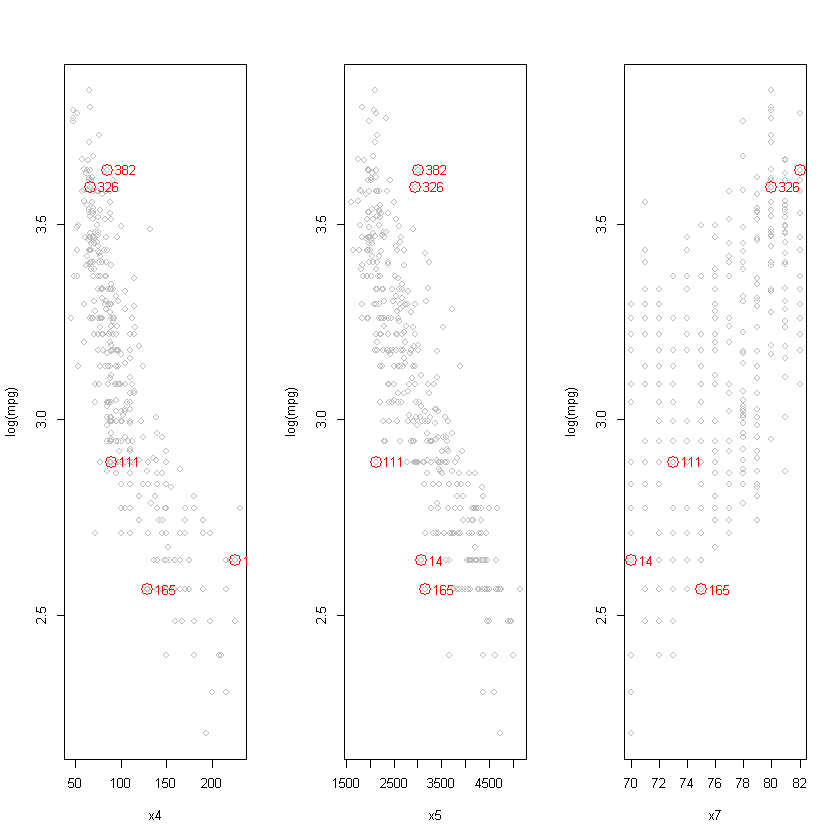

In [12]:

# (e) Pontos alavanca / discrepantes / influentes: ajuste com e sem
pontos <- c(14, 111, 165, 326, 382)
par(mfrow=c(1,3))
for (v in c("x4","x5","x7")) {
  plot(auto[[v]], log(auto$y), xlab=v, ylab="log(mpg)", col="gray")
  points(auto[[v]][pontos], log(auto$y)[pontos], col="red", pch=1, cex=2)
  text(auto[[v]][pontos], log(auto$y)[pontos], pontos, pos=4, col="red")
}
par(mfrow=c(1,1))
auto[pontos, ]
aj_final_sem <- glm(y ~ x2 + x3 + x4 + x5 + x7 + x8,
                    family=Gamma(link="log"), data=auto, subset=-pontos)
summary(aj_final_sem)
100*(coefficients(aj_final_sem)/coefficients(aj_final) - 1)
for (i in pontos){
  aj_i <- glm(y ~ x2 + x3 + x4 + x5 + x7 + x8,
              family=Gamma(link="log"), data=auto, subset=-i)
  cat("Sem o ponto", i, "\n"); print(summary(aj_i)$coefficients)
}

# (f) Pseudo R2
1 - aj_final$deviance/aj_final$null.deviance
cor(auto$y, fitted(aj_final))^2

In [15]:
#########################################################################
# EXERCICIO 4
#########################################################################
library(lmtest)
# (a) Teste de Wald para X8: H0: beta_x82 = beta_x83 = 0
library(car)
names(coefficients(aj_final))
L4a <- rbind(c(0,0,0,0,0,0,1,0),
             c(0,0,0,0,0,0,0,1))
linearHypothesis(aj_final, hypothesis.matrix=L4a)
b2 <- coefficients(aj_final)[7:8]
V2 <- vcov(aj_final)[7:8, 7:8]
W <- drop(t(b2) %*% solve(V2) %*% b2)
W; 1 - pchisq(W, 2)

# (b) Niveis 1 vs 2 e 1 vs 3
library(car)
names(coefficients(aj_final))
linearHypothesis(aj_final, hypothesis.matrix=c(0,0,0,0,0,0,1,0))
linearHypothesis(aj_final, hypothesis.matrix=c(0,0,0,0,0,0,0,1))

# (c) IC para a razao de medias nivel 3 / nivel 2 = exp(beta_x83 - beta_x82)
b  <- coefficients(aj_final); V <- vcov(aj_final)
a  <- c(0,0,0,0,0,0,-1,1)
est <- sum(a*b); ep <- sqrt(t(a)%*%V%*%a)
tcrit <- qt(0.975, df=aj_final$df.residual)
exp(c(est, est - tcrit*ep, est + tcrit*ep))
linearHypothesis(aj_final, hypothesis.matrix=a)

# (d) IC para a media: x2=4, x3=150, x4=100, x5=2300, x6=17, x7=80, x8=1
novo <- data.frame(x2=4, x3=150, x4=100, x5=2300, x6=17, x7=80,
                   x8=factor(1, levels=c("1","2","3")))
pr <- predict(aj_final, newdata=novo, type="link", se.fit=TRUE)
exp(pr$fit + c(0, -1, 1)*qt(0.975, aj_final$df.residual)*pr$se.fit)

# (e) Categorizar x7 (model year) e usar como fator
table(auto$x7)
auto$x7c <- cut(auto$x7, breaks=c(69,73,77,82), labels=c("70-73","74-77","78-82"))
aj_x7c <- glm(y ~ x2 + x3 + x4 + x5 + x7c + x8,
              family=Gamma(link="log"), data=auto)
summary(aj_x7c)
AIC(aj_final, aj_x7c)

# (f) Interacao entre X8 e as demais preditoras
aj_int <- glm(y ~ (x2 + x3 + x4 + x5 + x7)*x8,
              family=Gamma(link="log"), data=auto)
summary(aj_int)
anova(aj_final, aj_int, test="F")
lrtest(aj_final, aj_int)
AIC(aj_final, aj_int)
aj_int2 <- glm(y ~ x2 + x3 + x4 + x5 + x7 + x8 + x4:x8,
               family=Gamma(link="log"), data=auto)
summary(aj_int2)
anova(aj_final, aj_int2, test="F")
drop1(aj_int, test="F")


Carregando pacotes exigidos: zoo


Anexando pacote: 'zoo'


Os seguintes objetos são mascarados por 'package:base':

    as.Date, as.Date.numeric




[1] "(Intercept)" "x2"          "x3"          "x4"          "x5"         
[6] "x7"          "x82"         "x83"

,Res.Df,Df,Chisq,Pr(>Chisq)
,<dbl>,<dbl>,<dbl>,<dbl>
1,386,NA,NA,NA
2,384,2,26.13643,2.111286e-06


[1] 26.13643

[1] 2.111286e-06

[1] "(Intercept)" "x2"          "x3"          "x4"          "x5"         
[6] "x7"          "x82"         "x83"

... (11 outputs left out)

,df,AIC
,<dbl>,<dbl>
aj_final,9,1874.323
aj_int,19,1856.970



Call:
glm(formula = y ~ x2 + x3 + x4 + x5 + x7 + x8 + x4:x8, family = Gamma(link = "log"), 
    data = auto)

Coefficients:
              Estimate Std. Error t value Pr(>|t|)    
(Intercept)  1.610e+00  1.468e-01  10.969  < 2e-16 ***
x2          -2.718e-02  1.110e-02  -2.447 0.014838 *  
x3           3.302e-04  2.856e-04   1.156 0.248286    
x4          -4.923e-04  4.203e-04  -1.171 0.242156    
x5          -2.447e-04  2.093e-05 -11.692  < 2e-16 ***
x7           3.066e-02  1.789e-03  17.140  < 2e-16 ***
x82          3.599e-01  6.473e-02   5.560 5.07e-08 ***
x83          2.454e-01  6.605e-02   3.715 0.000233 ***
x4:x82      -3.475e-03  7.857e-04  -4.422 1.27e-05 ***
x4:x83      -2.094e-03  7.990e-04  -2.621 0.009109 ** 
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for Gamma family taken to be 0.0130983)

    Null deviance: 44.2046  on 391  degrees of freedom
Residual deviance:  5.0155  on 382  degrees of freedom
AIC: 1855.7

Number of Fisher

,Resid. Df,Resid. Dev,Df,Deviance,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,384,5.312260,NA,NA,NA,NA
2,382,5.015505,2,0.2967544,11.32797,1.662231e-05


,Df,Deviance,AIC,F value,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
<none>,NA,4.830432,1856.970,NA,NA
x2:x8,2,4.862590,1855.453,1.2449368,0.2891496092
x3:x8,2,4.852946,1854.709,0.8715785,0.4191386092
x4:x8,2,5.036134,1868.853,7.9633504,0.0004103678
x5:x8,2,4.884024,1857.108,2.0747115,0.1270357519
x7:x8,2,4.840506,1853.748,0.3900234,0.6773160868



Call:
glm(formula = y ~ x2 + x3 + x4 + x5 + x7 + x8, family = Gamma(link = "inverse"), 
    data = auto)

Coefficients:
              Estimate Std. Error t value Pr(>|t|)    
(Intercept)  9.904e-02  6.082e-03  16.282  < 2e-16 ***
x2           7.142e-04  5.561e-04   1.284  0.19978    
x3          -5.340e-06  1.376e-05  -0.388  0.69812    
x4           8.984e-05  1.813e-05   4.955 1.08e-06 ***
x5           1.036e-05  9.889e-07  10.479  < 2e-16 ***
x7          -1.241e-03  7.187e-05 -17.271  < 2e-16 ***
x82         -2.263e-03  7.294e-04  -3.103  0.00206 ** 
x83         -1.346e-03  6.855e-04  -1.964  0.05024 .  
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for Gamma family taken to be 0.01311919)

    Null deviance: 44.2046  on 391  degrees of freedom
Residual deviance:  4.9954  on 384  degrees of freedom
AIC: 1850.2

Number of Fisher Scoring iterations: 4



Call:
glm(formula = y ~ x2 + x3 + x4 + x5 + x7 + x8, family = Gamma(link = "identity"), 
    data = auto, start = c(mean(auto$y), rep(0, 7)))

Coefficients:
              Estimate Std. Error t value Pr(>|t|)    
(Intercept) -8.0848837  3.9014399  -2.072 0.038906 *  
x2          -1.0207671  0.2398637  -4.256 2.62e-05 ***
x3           0.0168869  0.0049991   3.378 0.000805 ***
x4          -0.0115657  0.0077885  -1.485 0.138375    
x5          -0.0046525  0.0004166 -11.168  < 2e-16 ***
x7           0.6282076  0.0478828  13.120  < 2e-16 ***
x82          2.3116954  0.5821903   3.971 8.56e-05 ***
x83          3.2136542  0.6007725   5.349 1.52e-07 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for Gamma family taken to be 0.01850746)

    Null deviance: 44.2046  on 391  degrees of freedom
Residual deviance:  7.1136  on 384  degrees of freedom
AIC: 1989.1

Number of Fisher Scoring iterations: 7


,df,AIC
,<dbl>,<dbl>
aj_g_log,9,1874.323
aj_g_inv,9,1850.160
aj_g_id,9,1989.085


[1] 0.8798257 0.8869943 0.8390750

Proporcao fora do envelope: 0.3239796 
Proporcao fora do envelope: 0.4056122 



Call:
glm(formula = y ~ x2 + x3 + x4 + x5 + x7 + x8, family = gaussian(link = "log"), 
    data = auto, start = c(log(mean(auto$y)), rep(0, 7)), maxit = 50)

Coefficients:
              Estimate Std. Error t value Pr(>|t|)    
(Intercept)  1.552e+00  1.512e-01  10.266  < 2e-16 ***
x2          -4.937e-03  1.379e-02  -0.358 0.720528    
x3           4.858e-04  3.447e-04   1.409 0.159556    
x4          -2.084e-03  4.534e-04  -4.595 5.87e-06 ***
x5          -2.721e-04  2.496e-05 -10.900  < 2e-16 ***
x7           3.264e-02  1.802e-03  18.112  < 2e-16 ***
x82          7.956e-02  1.845e-02   4.313 2.05e-05 ***
x83          6.341e-02  1.732e-02   3.662 0.000285 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for gaussian family taken to be 8.282027)

    Null deviance: 23819.0  on 391  degrees of freedom
Residual deviance:  3180.3  on 384  degrees of freedom
AIC: 1951.1

Number of Fisher Scoring iterations: 6



Call:
glm(formula = y ~ x2 + x3 + x4 + x5 + x7 + x8, family = inverse.gaussian(link = "log"), 
    data = auto, start = c(log(mean(auto$y)), rep(0, 7)), maxit = 50)

Coefficients:
              Estimate Std. Error t value Pr(>|t|)    
(Intercept)  1.7415253  0.1514516  11.499  < 2e-16 ***
x2          -0.0367031  0.0103999  -3.529 0.000467 ***
x3           0.0009587  0.0002379   4.030 6.72e-05 ***
x4          -0.0013389  0.0003503  -3.822 0.000154 ***
x5          -0.0002620  0.0000186 -14.086  < 2e-16 ***
x7           0.0297701  0.0018657  15.957  < 2e-16 ***
x82          0.0931308  0.0214349   4.345 1.79e-05 ***
x83          0.0934996  0.0214686   4.355 1.71e-05 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for inverse.gaussian family taken to be 0.0006201359)

    Null deviance: 2.02706  on 391  degrees of freedom
Residual deviance: 0.24606  on 384  degrees of freedom
AIC: 1883.7

Number of Fisher Scoring iterations: 5


,df,AIC
,<dbl>,<dbl>
aj_g_log,9,1874.323
aj_n_log,9,1951.087
aj_ig_log,9,1883.675


Proporcao fora do envelope: 0.6709184 


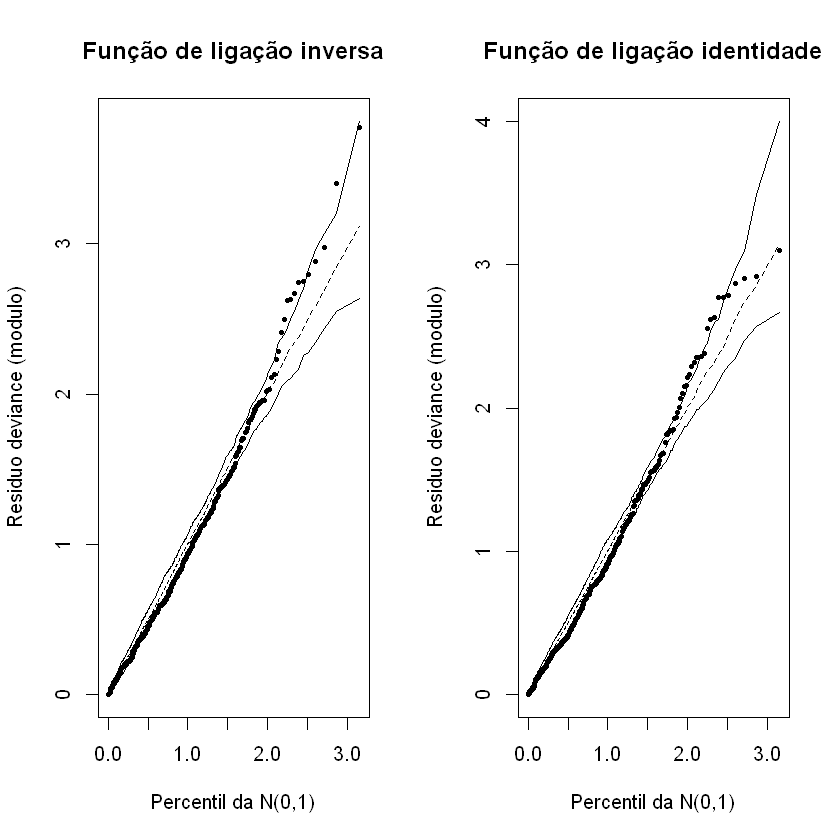

Proporcao fora do envelope: 0.3954082 


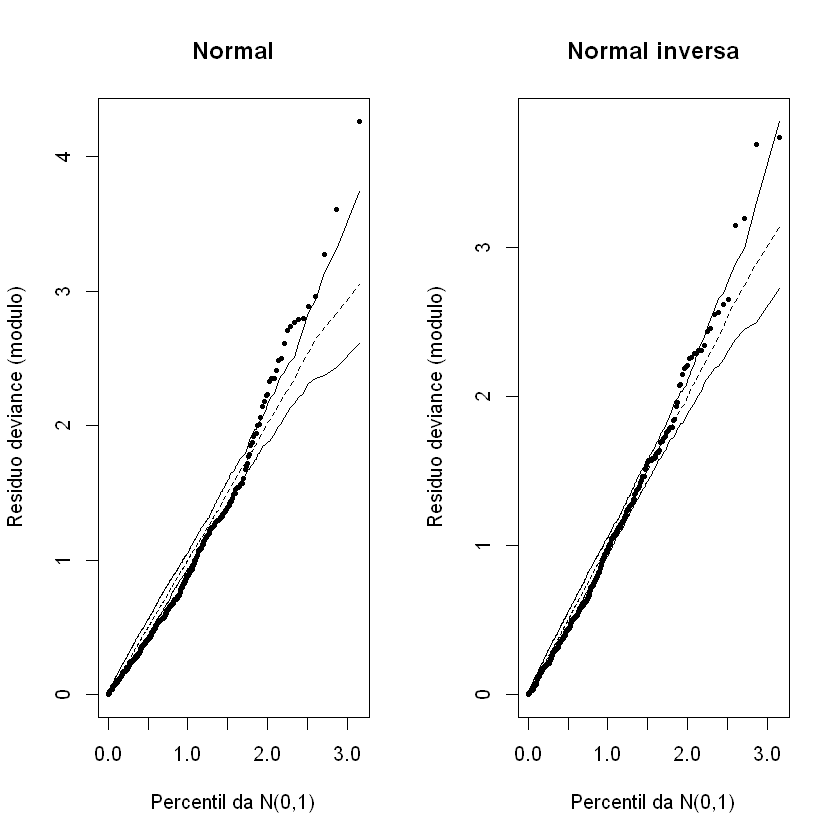

In [14]:
#########################################################################
# EXERCICIO 5
#########################################################################

# (a) Outras funcoes de ligacao para a gama
aj_g_log <- aj_final
aj_g_inv <- glm(y ~ x2 + x3 + x4 + x5 + x7 + x8,
                family=Gamma(link="inverse"), data=auto)
summary(aj_g_inv)
aj_g_id  <- glm(y ~ x2 + x3 + x4 + x5 + x7 + x8,
                family=Gamma(link="identity"), data=auto,
                start=c(mean(auto$y), rep(0, 7)))
summary(aj_g_id)

AIC(aj_g_log, aj_g_inv, aj_g_id)
sapply(list(aj_g_log, aj_g_inv, aj_g_id),
       function(m) 1 - m$deviance/m$null.deviance)

par(mfrow= c(1,2))
envelope_glm(aj_g_inv, auto)
title(main = "Função de ligação inversa")
envelope_glm(aj_g_id,  auto)
title(main = "Função de ligação identidade")

# (b) Outras distribuicoes (ligacao logaritmica)
aj_n_log  <- glm(y ~ x2 + x3 + x4 + x5 + x7 + x8,
                 family=gaussian(link="log"), data=auto,
                 start=c(log(mean(auto$y)), rep(0, 7)), maxit=50)
summary(aj_n_log)
aj_ig_log <- glm(y ~ x2 + x3 + x4 + x5 + x7 + x8,
                 family=inverse.gaussian(link="log"), data=auto,
                 start=c(log(mean(auto$y)), rep(0, 7)), maxit=50)
summary(aj_ig_log)

AIC(aj_g_log, aj_n_log, aj_ig_log)

par(mfrow= c(1,2))
envelope_glm(aj_n_log,  auto)
title(main = "Normal")
envelope_glm(aj_ig_log, auto)
title(main = "Normal inversa")